DATASET OVERVIEW
Shape: 2559 records, 21 columns
Default rate: 29.9%

Missing values:
Loan_Duration_Months     76
Loan_Amount             127
Employment_Duration     102
Age                     103

Loan_Amount min value (check for negatives): -5410 DM
DATA CLEANING SUMMARY
Variable                       Issue                Method
-------------------------------------------------------
Loan_Amount (negatives)        min = -5,410 DM      Clipped to 0
Loan_Duration_Months           76 missing (3%)      Median = 18 mo.
Loan_Amount                    127 missing (5%)     Median = 2322 DM
Age                            103 missing (4%)     Mean = 35 yrs
Employment_Duration            102 missing (4%)     Middle tier = '1-4 years'

Missing values remaining: 0


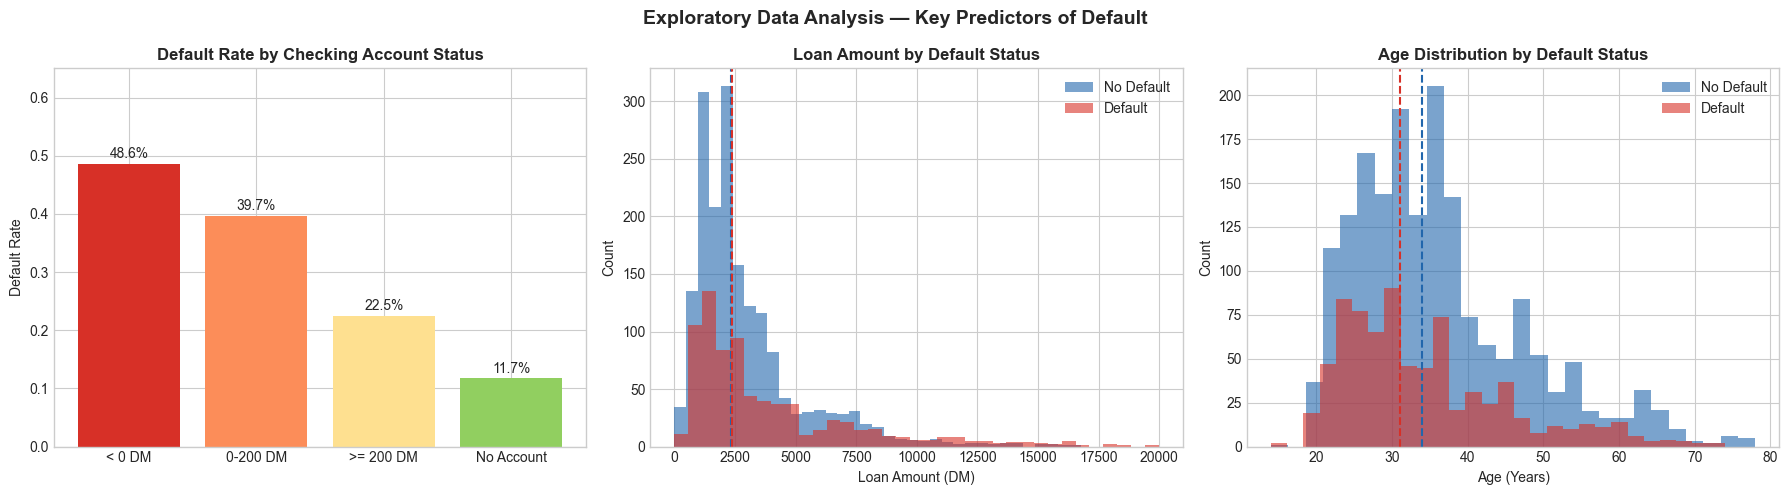

TRAIN/TEST SPLIT — Train: 2047  |  Test: 512

Model 1 — LR Baseline (All Features)
  Confusion Matrix → TN=318  FP=41  FN=73  TP=80
  Accuracy=0.7773  Precision=0.6612  Recall=0.5229  F1=0.5839  AUC=0.7898

  Top 5 Predictors (Odds Ratios):
    Checking_Account_Status                       OR=0.468  ↓ decreases default odds
    Installment_Rate_Pct                          OR=1.398  ↑ increases default odds
    Loan_Purpose_car (new)                        OR=1.389  ↑ increases default odds
    Loan_Duration_Months                          OR=1.378  ↑ increases default odds
    Loan_Amount                                   OR=1.364  ↑ increases default odds

Model 2 — LR Optimized (RFE, 15 features)
  Confusion Matrix → TN=322  FP=37  FN=79  TP=74
  Accuracy=0.7734  Precision=0.6667  Recall=0.4837  F1=0.5606  AUC=0.7951
  Selected features: ['Checking_Account_Status', 'Loan_Duration_Months', 'Loan_Amount', 'Savings_Account_Status', 'Installment_Rate_Pct', 'Is_Foreign_Worker', 'Credit_H

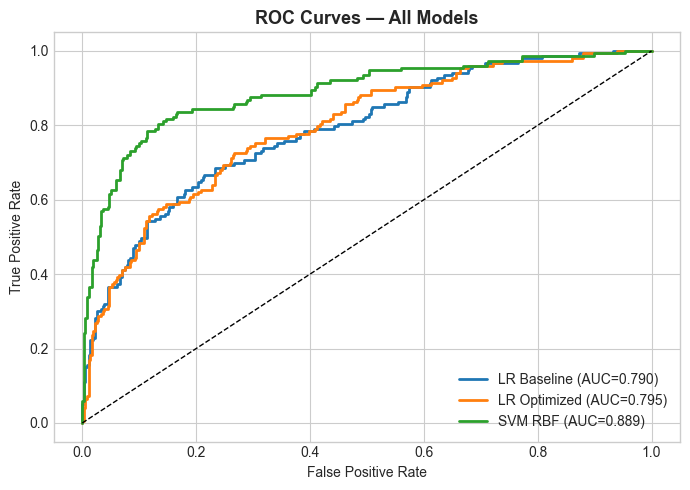

In [5]:
# ALY6020 - Project 3 | Loan Default Prediction | SecureBank
# Classification Models: Logistic Regression & SVM
# Dev Panchal

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')

from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.metrics import (confusion_matrix, accuracy_score,
                             precision_score, recall_score, f1_score,
                             roc_curve, roc_auc_score)
from sklearn.feature_selection import RFE

# LOAD DATA 
df = pd.read_csv('loan_default.csv')

print("DATASET OVERVIEW")

print(f"Shape: {df.shape[0]} records, {df.shape[1]} columns")
print(f"Default rate: {df['Loan_Default'].value_counts(normalize=True)['Yes']:.1%}")
print(f"\nMissing values:")
missing = df.isnull().sum()
print(missing[missing > 0].to_string())
print(f"\nLoan_Amount min value (check for negatives): {df['Loan_Amount'].min():.0f} DM")

# DATA CLEANING 
df['Loan_Amount'] = df['Loan_Amount'].clip(lower=0)

duration_median = df['Loan_Duration_Months'].median()
df.loc[df['Loan_Duration_Months'].isnull(), 'Loan_Duration_Months'] = duration_median

amount_median = df['Loan_Amount'].median()
df.loc[df['Loan_Amount'].isnull(), 'Loan_Amount'] = amount_median

age_mean = df['Age'].mean()
df.loc[df['Age'].isnull(), 'Age'] = age_mean

df.loc[df['Employment_Duration'].isnull(), 'Employment_Duration'] = '1 - 4 years'

print("DATA CLEANING SUMMARY")

print(f"{'Variable':<30} {'Issue':<20} {'Method'}")
print("-" * 55)
print(f"{'Loan_Amount (negatives)':<30} {'min = -5,410 DM':<20} Clipped to 0")
print(f"{'Loan_Duration_Months':<30} {'76 missing (3%)':<20} Median = {duration_median:.0f} mo.")
print(f"{'Loan_Amount':<30} {'127 missing (5%)':<20} Median = {amount_median:.0f} DM")
print(f"{'Age':<30} {'103 missing (4%)':<20} Mean = {age_mean:.0f} yrs")
print(f"{'Employment_Duration':<30} {'102 missing (4%)':<20} Middle tier = '1-4 years'")
print(f"\nMissing values remaining: {df.isnull().sum().sum()}")

# ENCODING 
df['Loan_Default'] = (df['Loan_Default'] == 'Yes').astype(int)

checking_map = {'< 0 DM': 0, '0 - 200 DM': 1, '>= 200 DM': 2, 'no checking account': 3}
savings_map  = {'< 100 DM': 0, '100 - 500 DM': 1, '500 - 1000 DM': 2,
                '>= 1000 DM': 3, 'unknown / no savings': 4}
emp_map      = {'unemployed': 0, '< 1 year': 1, '1 - 4 years': 2,
                '4 - 7 years': 3, '>= 7 years': 4}

df['Checking_Account_Status'] = df['Checking_Account_Status'].map(checking_map)
df['Savings_Account_Status']  = df['Savings_Account_Status'].map(savings_map)
df['Employment_Duration']     = df['Employment_Duration'].map(emp_map)

le = LabelEncoder()
for col in ['Has_Telephone', 'Is_Foreign_Worker']:
    df[col] = le.fit_transform(df[col])

nominal_cols = ['Credit_History', 'Loan_Purpose', 'Personal_Status',
                'Other_Debtors_Guarantors', 'Property_Type',
                'Other_Installment_Plans', 'Housing_Type', 'Job_Type']
df = pd.get_dummies(df, columns=nominal_cols, drop_first=True)

# EDA VISUALIZATIONS 
plt.style.use('seaborn-v0_8-whitegrid')
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
fig.suptitle('Exploratory Data Analysis — Key Predictors of Default', fontsize=14, fontweight='bold')

checking_labels = {0: '< 0 DM', 1: '0-200 DM', 2: '>= 200 DM', 3: 'No Account'}
df['Checking_Label'] = df['Checking_Account_Status'].map(checking_labels)
dcr = df.groupby('Checking_Label')['Loan_Default'].mean().sort_values(ascending=False).reset_index()
bars = axes[0].bar(dcr['Checking_Label'], dcr['Loan_Default'],
                   color=['#d73027', '#fc8d59', '#fee090', '#91cf60'])
axes[0].set_title('Default Rate by Checking Account Status', fontweight='bold')
axes[0].set_ylabel('Default Rate')
axes[0].set_ylim(0, 0.65)
for bar, val in zip(bars, dcr['Loan_Default']):
    axes[0].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.01,
                 f'{val:.1%}', ha='center', fontsize=10)
df.drop('Checking_Label', axis=1, inplace=True)

no_def  = df[df['Loan_Default'] == 0]
yes_def = df[df['Loan_Default'] == 1]
axes[1].hist(no_def['Loan_Amount'],  bins=35, alpha=0.6, label='No Default', color='#2166ac')
axes[1].hist(yes_def['Loan_Amount'], bins=35, alpha=0.6, label='Default',    color='#d73027')
axes[1].axvline(no_def['Loan_Amount'].median(),  color='#2166ac', linestyle='--', linewidth=1.5)
axes[1].axvline(yes_def['Loan_Amount'].median(), color='#d73027', linestyle='--', linewidth=1.5)
axes[1].set_title('Loan Amount by Default Status', fontweight='bold')
axes[1].set_xlabel('Loan Amount (DM)')
axes[1].set_ylabel('Count')
axes[1].legend()

axes[2].hist(no_def['Age'],  bins=28, alpha=0.6, label='No Default', color='#2166ac')
axes[2].hist(yes_def['Age'], bins=28, alpha=0.6, label='Default',    color='#d73027')
axes[2].axvline(no_def['Age'].median(),  color='#2166ac', linestyle='--', linewidth=1.5)
axes[2].axvline(yes_def['Age'].median(), color='#d73027', linestyle='--', linewidth=1.5)
axes[2].set_title('Age Distribution by Default Status', fontweight='bold')
axes[2].set_xlabel('Age (Years)')
axes[2].set_ylabel('Count')
axes[2].legend()

plt.tight_layout()
plt.savefig('eda_plots.png', dpi=150, bbox_inches='tight')
plt.show()

# MODEL BUILDING 
X = df.drop('Loan_Default', axis=1)
y = df['Loan_Default']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)

scaler = StandardScaler()
X_train_sc = scaler.fit_transform(X_train)
X_test_sc  = scaler.transform(X_test)

def get_metrics(y_true, y_pred, y_prob):
    return {
        'Accuracy':  round(accuracy_score(y_true, y_pred), 4),
        'Precision': round(precision_score(y_true, y_pred), 4),
        'Recall':    round(recall_score(y_true, y_pred), 4),
        'F1':        round(f1_score(y_true, y_pred), 4),
        'AUC':       round(roc_auc_score(y_true, y_prob), 4)
    }

def print_model(name, y_true, y_pred, y_prob):
    cm = confusion_matrix(y_true, y_pred)
    m  = get_metrics(y_true, y_pred, y_prob)
    print(f"\n{name}")
    print(f"  Confusion Matrix → TN={cm[0,0]}  FP={cm[0,1]}  FN={cm[1,0]}  TP={cm[1,1]}")
    print(f"  Accuracy={m['Accuracy']}  Precision={m['Precision']}  "
          f"Recall={m['Recall']}  F1={m['F1']}  AUC={m['AUC']}")


print(f"TRAIN/TEST SPLIT — Train: {X_train.shape[0]}  |  Test: {X_test.shape[0]}")


# Model 1 — LR Baseline
lr1 = LogisticRegression(max_iter=1000, random_state=42)
lr1.fit(X_train_sc, y_train)
y_pred1 = lr1.predict(X_test_sc)
y_prob1 = lr1.predict_proba(X_test_sc)[:, 1]
print_model("Model 1 — LR Baseline (All Features)", y_test, y_pred1, y_prob1)

coef_df = pd.DataFrame({
    'Feature':    X.columns,
    'Odds_Ratio': np.exp(lr1.coef_[0])
}).sort_values('Odds_Ratio', key=lambda x: abs(x - 1), ascending=False)

print("\n  Top 5 Predictors (Odds Ratios):")
for _, row in coef_df.head(5).iterrows():
    direction = "↑ increases" if row['Odds_Ratio'] > 1 else "↓ decreases"
    print(f"    {row['Feature']:<45} OR={row['Odds_Ratio']:.3f}  {direction} default odds")

# Model 2 — LR Optimized (RFE)
rfe = RFE(LogisticRegression(max_iter=1000, random_state=42), n_features_to_select=15)
rfe.fit(X_train_sc, y_train)
selected = X.columns[rfe.support_].tolist()
X_train_rfe = X_train_sc[:, rfe.support_]
X_test_rfe  = X_test_sc[:, rfe.support_]

lr2 = LogisticRegression(max_iter=1000, random_state=42)
lr2.fit(X_train_rfe, y_train)
y_pred2 = lr2.predict(X_test_rfe)
y_prob2 = lr2.predict_proba(X_test_rfe)[:, 1]
print_model("Model 2 — LR Optimized (RFE, 15 features)", y_test, y_pred2, y_prob2)
print(f"  Selected features: {selected}")

# Model 3 — SVM RBF
svm = SVC(kernel='rbf', probability=True, random_state=42)
svm.fit(X_train_sc, y_train)
y_pred3 = svm.predict(X_test_sc)
y_prob3 = svm.predict_proba(X_test_sc)[:, 1]
print_model("Model 3 — SVM (RBF Kernel)", y_test, y_pred3, y_prob3)

#  MODEL COMPARISON + ROC 

print("MODEL COMPARISON SUMMARY")

results = [
    ("LR Baseline",  y_pred1, y_prob1),
    ("LR Optimized", y_pred2, y_prob2),
    ("SVM RBF",      y_pred3, y_prob3),
]
summary = []
for name, yp, ypr in results:
    m = get_metrics(y_test, yp, ypr)
    summary.append({'Model': name, **m})
    print(f"  {name:<15} Acc={m['Accuracy']}  Prec={m['Precision']}  "
          f"Rec={m['Recall']}  F1={m['F1']}  AUC={m['AUC']}")

fig, ax = plt.subplots(figsize=(7, 5))
for name, _, y_prob in results:
    fpr, tpr, _ = roc_curve(y_test, y_prob)
    auc = roc_auc_score(y_test, y_prob)
    ax.plot(fpr, tpr, linewidth=2, label=f'{name} (AUC={auc:.3f})')
ax.plot([0, 1], [0, 1], 'k--', linewidth=1)
ax.set_xlabel('False Positive Rate')
ax.set_ylabel('True Positive Rate')
ax.set_title('ROC Curves — All Models', fontsize=13, fontweight='bold')
ax.legend(loc='lower right')
plt.tight_layout()
plt.savefig('roc_curves.png', dpi=150, bbox_inches='tight')
plt.show()


